# 03 · Association Rule Mining — FinSight AI
**Phase 4 · Subject: DMW** · KDD steps **4 (Transformation → items)**, **5 (Data Mining)** and **6 (Pattern Evaluation)**

**Research question RQ2:** *What recurring combinations of transaction behaviours does association-rule mining discover, and how do Apriori and FP-Growth compare?*

| Step | What | Module |
|---|---|---|
| 4 Transformation | 20 behaviour/amount/context/network items + 2 label items | `finsight.mining.discretiser` |
| 5 Mining | Apriori, FP-Growth, FP-Max (maximal), closed itemsets | `finsight.mining.association` |
| 6 Evaluation | support / confidence / lift / leverage / conviction; Lift > 1.5 & Conf > 0.6; productive-rule pruning; emerging patterns | `finsight.mining.association` |

The expensive experiments (benchmark grid, PaySim 6.36M rows) are run by `make pipeline STAGES=mining` and loaded here from `reports/`. India rules are re-mined live (< 1 s).

In [1]:
import warnings, json, ast; warnings.filterwarnings("ignore")
import pandas as pd
from IPython.display import display
from finsight import viz, config
from finsight.eda import load_master
from finsight.mining import association as A, report as R
from finsight.mining.discretiser import india_items, item_table, to_baskets, INDIA_ITEM_RULES
viz.apply_style()
pd.set_option("display.max_colwidth", 90, "display.width", 180)
m10, m11 = load_master("v1_0"), load_master("v1_1")
summary = json.loads((config.REPORTS_DIR / "mining_summary.json").read_text())

## 1 · KDD step 4: from features to items (market-basket view)

In [2]:
items = india_items(m11)
print(f"{items.shape[0]:,} transactions × {items.shape[1]} items  (avg {items.sum(axis=1).mean():.1f} items per basket)")
for tid, basket in zip(m11["transaction_id"][:3], to_baskets(items.head(3))):
    print(tid, basket)
display(item_table(items, m11))

10,000 transactions × 22 items  (avg 2.8 items per basket)
TXN_IND_202608_000117 ['ODD_HOUR', 'CH_UPI']
TXN_IND_202608_002343 ['NEW_DEVICE', 'NEW_BENEFICIARY', 'ODD_HOUR', 'CH_UPI']
TXN_IND_202608_000446 ['MODERATE_AMOUNT_SPIKE', 'HIGH_VALUE', 'RECENT_BENEFICIARY', 'FAR_FROM_HOME', 'ODD_HOUR', 'CH_UPI', 'BORDERLINE']


,item,rule,count,support,fraud_rate
0,HIGH_AMOUNT_SPIKE,amount_ratio_vs_30d_avg > 5,2683,0.2683,0.3321
1,MODERATE_AMOUNT_SPIKE,2 < amount_ratio_vs_30d_avg <= 5,1012,0.1012,0.2223
2,HIGH_VALUE,amount_inr >= 50000,1923,0.1923,0.3500
3,NEAR_THRESHOLD,45000 <= amount_inr < 50000,317,0.0317,0.7287
4,NEW_DEVICE,is_new_device == 1,2218,0.2218,0.3206
5,NEW_BENEFICIARY,is_new_beneficiary == 1,2444,0.2444,0.2676
6,RECENT_BENEFICIARY,time_since_beneficiary_added_min < 1440,906,0.0906,0.7616
7,FAR_FROM_HOME,distance_from_home_km > 100,575,0.0575,0.6574
8,EXTREME_LOCATION,distance_from_home_km > 500,250,0.0250,0.4040
9,ODD_HOUR,hour_of_day < 6 or hour_of_day > 22,1101,0.1101,0.1953


Each transaction becomes a **basket of items**. Thresholds come from the Phase 2 audit (Plan §6.4). Dead items from the original plan (`NEW_ACCOUNT` = 0 rows, `IMMEDIATE_REPEAT` = 2 rows) were dropped. The five **network items** (`PASS_THROUGH`, `QUICK_INFLOW`, `HUB_RECEIVER`, `BURST_SENDER`, `SHARED_DEVICE`) are point-in-time graph features from Phase 3. `FRAUDULENT` / `BORDERLINE` are **label items allowed only as rule consequents**.

## 2 · KDD step 5: Apriori vs FP-Growth benchmark

,items,n_items,n_rows,algorithm,min_support,itemsets,seconds,peak_mb
8,core,22,10000,apriori,0.010,534,0.014,15.1
9,core,22,10000,fpgrowth,0.010,534,0.036,1.1
10,core,22,10000,fpmax,0.010,96,0.035,0.8
11,core,22,10000,closed (from fpgrowth),0.010,469,NaN,NaN
16,core,22,10000,apriori,0.002,2840,0.058,60.8
17,core,22,10000,fpgrowth,0.002,2840,0.055,3.6
18,core,22,10000,fpmax,0.002,221,0.053,1.3
19,core,22,10000,closed (from fpgrowth),0.002,1849,NaN,NaN
28,extended,49,10000,apriori,0.010,6244,0.154,155.9
29,extended,49,10000,fpgrowth,0.010,6244,0.199,11.8


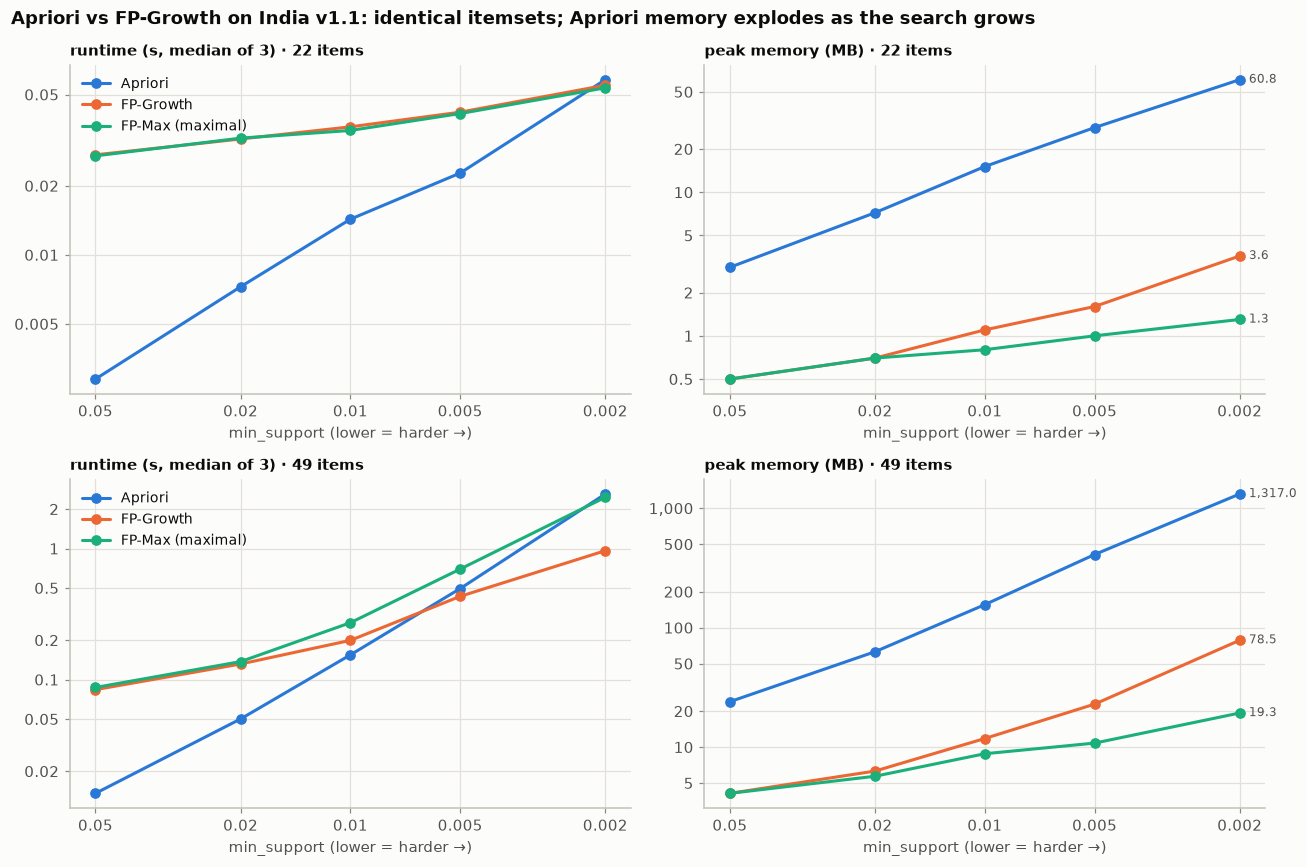

In [3]:
bench = pd.read_csv(config.REPORTS_DIR / "mining_benchmark.csv")
R.fig_benchmark(bench);
display(bench[bench.min_support.isin([0.01, 0.002])].round(3))

**Correctness:** at every support level and in both item universes, Apriori and FP-Growth returned **identical itemsets and supports** (asserted in code).

**Performance: the textbook story, but with a twist**
- **Memory:** Apriori materialises every candidate itemset as a column over all transactions, so its memory grows exponentially as the search widens: **1,317 MB vs 78.5 MB for FP-Growth (17× more)** at 49 items / support 0.002 (56,278 itemsets). FP-Growth compresses the data into a prefix tree.
- **Runtime:** with a *small* search (22 items, support ≥ 0.005), **Apriori is faster**, because mlxtend's Apriori is numpy-vectorised while its FP-Growth is pure Python. Once the search grows (49 items, support 0.002), FP-Growth overtakes it (≈1.0 s vs ≈2.6 s).
- **Lesson:** algorithmic complexity *and* implementation both matter. FP-Growth's advantage is real, and it shows where candidate explosion happens.

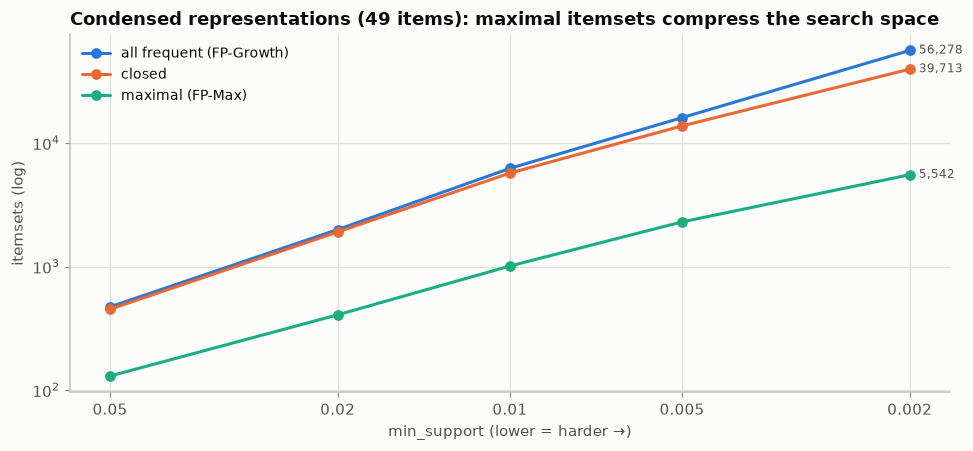

In [4]:
R.fig_condensed(bench);

**Condensed representations** at 49 items / support 0.002: 56,278 frequent → **39,713 closed** (lossless: every frequent itemset's support can be recovered) → **5,542 maximal** (FP-Max; lossy, but ~10× smaller). On the 22-item core set: 534 → 469 closed → 96 maximal at support 0.01.

,n_rows,algorithm,min_support,itemsets,distinct_baskets,seconds,peak_mb
0,100000,apriori,0.01,56,149,0.010,20.6
1,100000,fpgrowth,0.01,56,149,0.289,0.1
2,500000,apriori,0.01,57,173,0.055,103.0
3,500000,fpgrowth,0.01,57,173,1.458,0.1
4,1000000,apriori,0.01,57,185,0.125,206.0
5,1000000,fpgrowth,0.01,57,185,2.899,0.1
6,2000000,apriori,0.01,57,199,0.232,412.0
7,2000000,fpgrowth,0.01,57,199,5.820,NaN
8,6362620,apriori,0.01,57,228,0.745,1310.7
9,6362620,fpgrowth,0.01,57,228,17.297,NaN


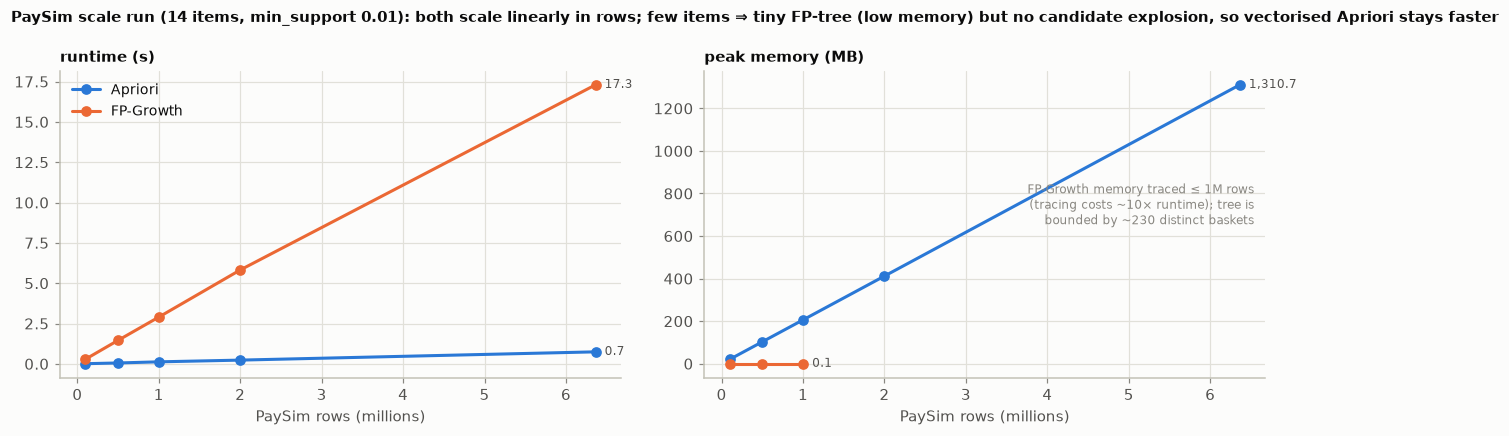

In [5]:
sc = pd.read_csv(config.REPORTS_DIR / "mining_paysim_scaling.csv")
R.fig_paysim_scaling(sc)
display(sc)

**PaySim scale run (6.36M rows, 14 items):** both algorithms scale **linearly in rows**. With only 14 items there are just ~230 distinct baskets, so the FP-tree is tiny (≈0.1 MB) and there's no candidate explosion; vectorised Apriori is therefore faster (< 1 s vs ≈ 18 s) but needs **1.3 GB**. Memory, not time, is where Apriori breaks first at scale.

*Runtimes vary ±10% between runs; memory is deterministic. Measurement protocol (D-017): runtimes come from untraced runs (median of 3); memory comes from a separate `tracemalloc` run, because tracing slows pure-Python FP-Growth ~10×.*

## 3 · KDD step 6: rules → FRAUDULENT / BORDERLINE (v1.1)

{'itemsets': 534, 'all': 168, 'filtered': 152, 'productive': 49}


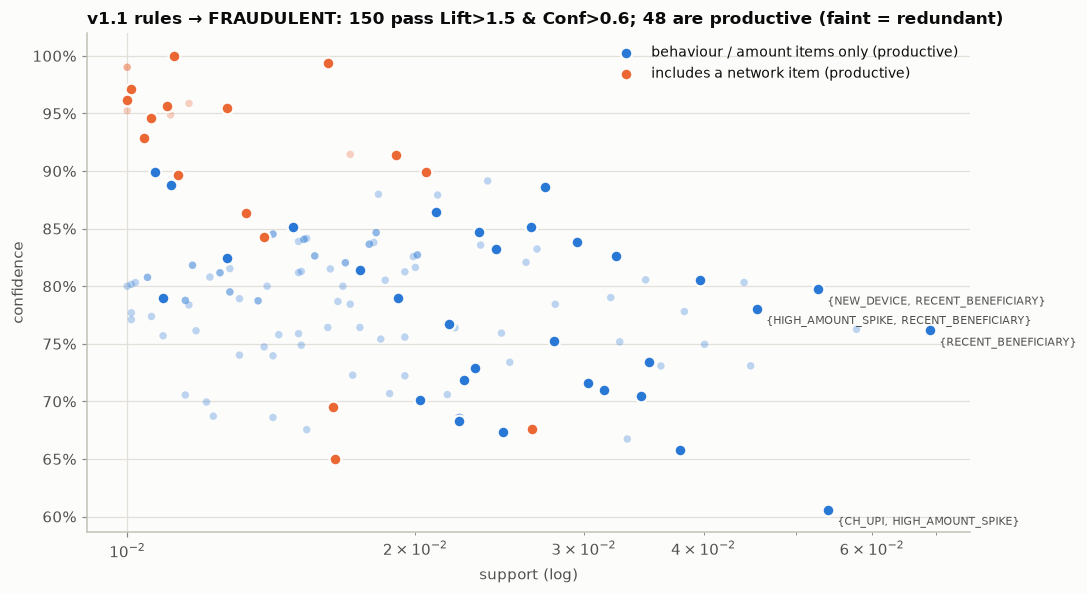

In [6]:
R11 = R.india_rules(m11)
print({k: len(R11[k]) for k in ("itemsets", "all", "filtered", "productive")})
R.fig_rules_scatter(R11["filtered"], R11["productive"]);

Funnel on v1.1 (min_support 0.01): **534 frequent itemsets → 168 target rules (conf ≥ 0.5) → 152 pass Lift > 1.5 & Conf > 0.6 → 49 productive rules**.

**Productive-rule pruning** (Bayardo's *improvement*): `X → c` is kept only if its confidence beats every simpler sub-rule `Y → c` (`Y ⊂ X`) by ≥ 0.01. Without it, the top-10 is filled with near-duplicates such as `{A, B, CH_UPI} → F` next to `{A, B} → F`.

,rule,support,confidence,lift,leverage,conviction
0,"{CH_UPI, HIGH_AMOUNT_SPIKE, HUB_RECEIVER} → FRAUDULENT",0.011,1.000,7.418,0.010,inf
1,{PASS_THROUGH} → FRAUDULENT,0.016,0.994,7.373,0.014,141.028
2,"{HIGH_AMOUNT_SPIKE, QUICK_INFLOW, RECENT_BENEFICIARY} → FRAUDULENT",0.010,0.971,7.204,0.009,29.994
3,"{HIGH_VALUE, NEW_BENEFICIARY, QUICK_INFLOW} → FRAUDULENT",0.010,0.962,7.133,0.009,22.495
4,"{HIGH_AMOUNT_SPIKE, NEW_DEVICE, QUICK_INFLOW} → FRAUDULENT",0.011,0.957,7.096,0.009,19.900
5,"{QUICK_INFLOW, RECENT_BENEFICIARY} → FRAUDULENT",0.013,0.955,7.084,0.011,19.179
6,"{HIGH_AMOUNT_SPIKE, NEW_BENEFICIARY, QUICK_INFLOW} → FRAUDULENT",0.011,0.946,7.021,0.009,16.150
7,"{NEW_BENEFICIARY, NEW_DEVICE, QUICK_INFLOW} → FRAUDULENT",0.010,0.929,6.889,0.009,12.113
8,"{HIGH_VALUE, QUICK_INFLOW} → FRAUDULENT",0.019,0.914,6.779,0.016,10.046
9,"{NEAR_THRESHOLD, RECENT_BENEFICIARY} → FRAUDULENT",0.011,0.899,6.670,0.009,8.580


,rule,support,confidence,lift
0,"{EXTREME_LOCATION, NEW_DEVICE} → BORDERLINE",0.013,0.604,13.358


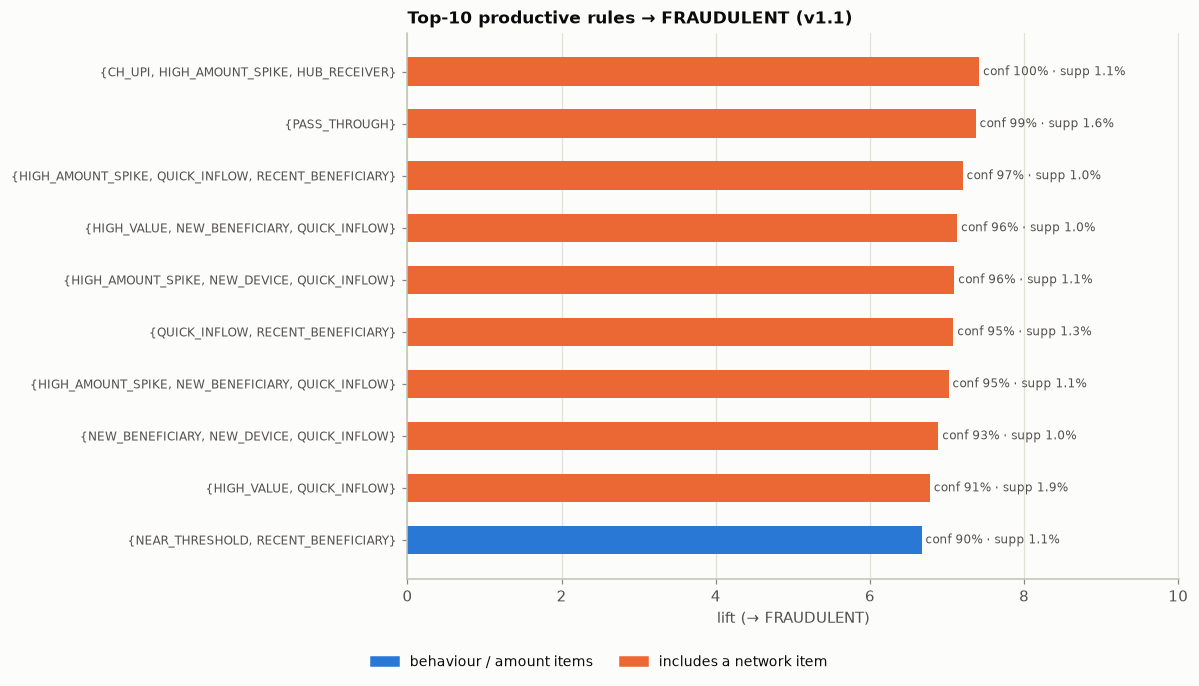

In [7]:
R.fig_top_rules(R11["productive"], "Top-10 productive rules → FRAUDULENT (v1.1)")
display(A.top_rules(R11["productive"], "FRAUDULENT", 10)[["rule", "support", "confidence", "lift", "leverage", "conviction"]].round(3))
display(R11["productive"].query("consequent == 'BORDERLINE'")[["rule", "support", "confidence", "lift"]].round(3))

**Top patterns (RQ2):**
1. `{PASS_THROUGH} → FRAUDULENT`: conf **99%**, lift 7.4, a single-item mule signature.
2. `{CH_UPI, HIGH_AMOUNT_SPIKE, HUB_RECEIVER} → FRAUDULENT`: conf **100%**, a large UPI payment into a fan-in hub (ring).
3. `QUICK_INFLOW` (money received < 1 h before sending) combined with any behaviour anomaly (recent beneficiary, new device, amount spike): conf 91–97%.
4. `{NEAR_THRESHOLD, RECENT_BENEFICIARY} → FRAUDULENT`: conf 90%, structuring just under ₹50k to a new payee.
5. The only BORDERLINE rule: `{EXTREME_LOCATION, NEW_DEVICE} → BORDERLINE`, conf 60% with **lift 13.4** (impossible-travel style, S10/S12).

9 of the top 10 rules contain a network item, but this is v1.1, where network structure was injected (D-001). See the control below.

## 4 · Control: v1.0 vs v1.1

,v1_0,v1_1
itemsets,493,534
closed,391,469
target_rules_conf_0.5,168,168
filtered_lift1.5_conf0.6,161,152
productive,34,49
productive_fraud_with_network_item,0,16


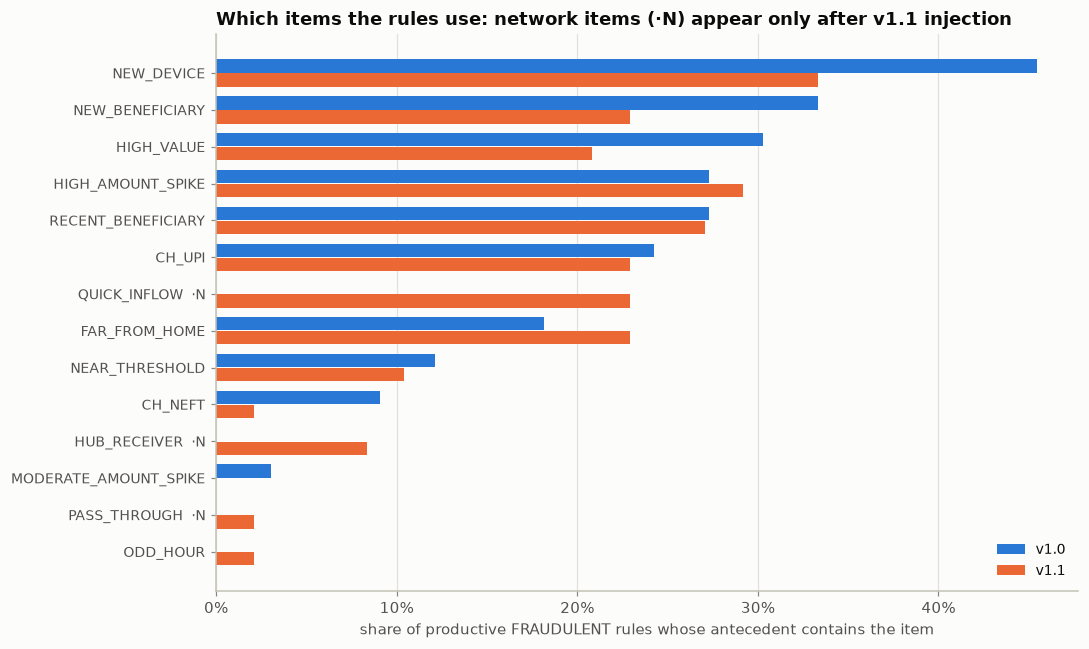

In [8]:
R10 = R.india_rules(m10)
R.fig_item_share(R10["productive"], R11["productive"])
display(pd.DataFrame({v: summary[v] for v in ("v1_0", "v1_1")}).drop("detector_all_productive_fraud_rules"))

- **v1.0:** 34 productive rules, **0 with a network item**. Rules are built from new device / new beneficiary / high value only.
- **v1.1:** 49 productive rules, **16 with a network item** (QUICK_INFLOW in 23% of rules, HUB_RECEIVER 8%, PASS_THROUGH 2%).
- Mining therefore **rediscovers exactly the structure that was injected, and nothing where none exists**, which independently validates both the v1.1 injection and the graph features.

## 5 · Fraud-subset mining: emerging patterns

In [9]:
ep = pd.read_csv(config.REPORTS_DIR / "emerging_patterns_v1_1.csv")
print(f"{len(ep)} minimal emerging patterns (support in fraud ≥ 5%, growth ≥ 3)")
display(ep.head(12)[["pattern", "support_target", "support_rest", "growth"]])

138 minimal emerging patterns (support in fraud ≥ 5%, growth ≥ 3)


,pattern,support_target,support_rest,growth
0,"{HIGH_AMOUNT_SPIKE, PASS_THROUGH}",0.083086,0.0,inf
1,"{CH_UPI, HIGH_AMOUNT_SPIKE, HUB_RECEIVER}",0.083086,0.0,inf
2,"{HIGH_VALUE, PASS_THROUGH}",0.072700,0.0,inf
3,"{CH_UPI, HIGH_VALUE, HUB_RECEIVER}",0.071958,0.0,inf
4,"{HUB_RECEIVER, RECENT_BENEFICIARY}",0.065282,0.0,inf
5,"{NEW_DEVICE, PASS_THROUGH}",0.063798,0.0,inf
6,"{CH_NEFT, NEW_DEVICE, RECENT_BENEFICIARY}",0.060089,0.0,inf
7,"{NEW_BENEFICIARY, PASS_THROUGH}",0.056380,0.0,inf
8,"{PASS_THROUGH, RECENT_BENEFICIARY}",0.055638,0.0,inf
9,"{HIGH_AMOUNT_SPIKE, HIGH_VALUE, NEW_DEVICE, QUICK_INFLOW, RECENT_BENEFICIARY}",0.055638,0.0,inf


Mining **only fraudulent transactions** (min_support 0.05) and contrasting with the rest gives **emerging patterns**: itemsets whose support *grows* from non-fraud to fraud. 138 minimal patterns (no subset already reaches the same growth) have growth ≥ 3. The strongest are **jumping emerging patterns** (growth = ∞: present in ≥ 5% of fraud, never in non-fraud), e.g. `{HIGH_AMOUNT_SPIKE, PASS_THROUGH}` in 8.3% of fraud and `{HUB_RECEIVER, RECENT_BENEFICIARY}` in 6.5%.

Contrast with full-dataset rules: emerging patterns describe *what fraud looks like from the inside*, while rules describe *how predictive a pattern is*.

## 6 · Rules as a transparent detector

all productive FRAUD rules: {'n_rules': 48, 'flagged': 2113, 'tp': 1227, 'fp': 886, 'fn': 121, 'precision': 0.5807, 'recall': 0.9102, 'f1': 0.709, 'fp_borderline': 426}
best F1: {'k': 39.0, 'precision': 0.678, 'recall': 0.858, 'f1': 0.758}


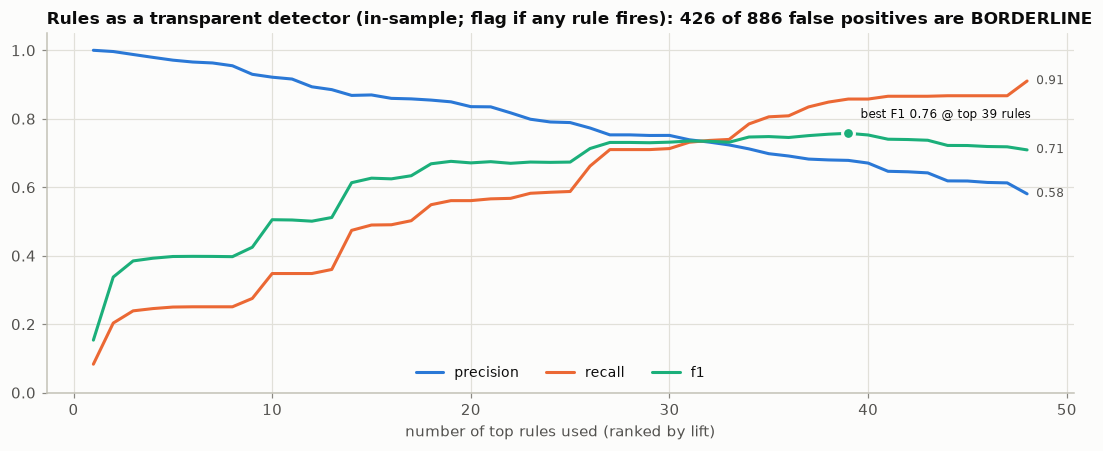

In [10]:
curve = R.detector_curve(R11["items"], R11["productive"], m11)
R.fig_detector_curve(curve, R11["detector"])
print("all productive FRAUD rules:", R11["detector"]); print("best F1:", curve.loc[curve.f1.idxmax()].round(3).to_dict())

Flag a transaction if any of the top-k rules (by lift) fires:
- The top 1–8 rules give **≥ 95% precision** at low recall.
- The best F1 is **0.76** with the top 39 rules (precision 0.68, recall 0.86).
- With all 48 rules, recall is 0.91 but precision drops to 0.58. **426 of the 886 false positives are BORDERLINE**: those rows match fraud patterns but are labelled non-fraud (the Phase 2 finding again).

⚠️ This evaluation is **in-sample** (rules mined and scored on the same 10K rows). It's descriptive. In Phase 5 the rules are re-mined on the training split and scored on the held-out test set alongside the ML models.

## 7 · PaySim (6.36M rows): rules at scale

,rule,support,confidence,lift
0,{ORIG_FULL_AMOUNT} → FRAUDULENT,0.00126,0.99002,766.96839
1,"{DEST_BALANCE_MISMATCH, DEST_ZERO_BEFORE, TYPE_TRANSFER} → FRAUDULENT",0.00064,0.42426,328.67567
2,"{DEST_BALANCE_MISMATCH, DEST_ZERO_BEFORE, ORIG_EMPTIED} → FRAUDULENT",0.00062,0.15337,118.81753
3,"{DEST_BALANCE_MISMATCH, ORIG_EMPTIED, TYPE_TRANSFER} → FRAUDULENT",0.00062,0.13847,107.27092


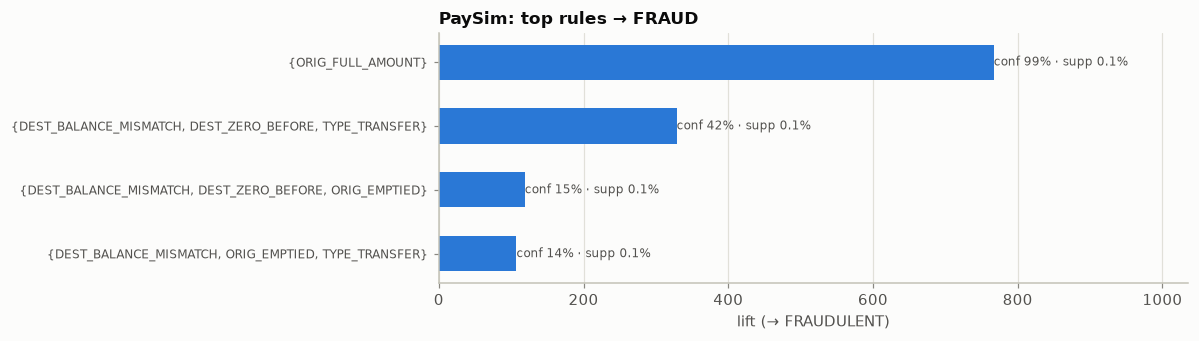

In [11]:
pr = pd.read_csv(config.REPORTS_DIR / "association_rules_paysim.csv")
pr["antecedents"] = pr["antecedents"].map(lambda s: frozenset(ast.literal_eval(s)))
R.fig_top_rules(pr, "PaySim: top rules → FRAUD", network_legend=False)
display(pr[["rule", "support", "confidence", "lift"]].round(5))

With a fraud rate of 0.13%, rules need min_support 0.0005 (≈3,200 rows). `{ORIG_FULL_AMOUNT} → FRAUD` (conf 99%, lift 767) is a known **simulator artifact**: PaySim fraud always empties the origin account. The other rules (destination balance inconsistencies on TRANSFERs) have lower confidence. This shows the same pipeline running on a 6.36M-row dataset in ~10 s (Apriori, which here is identical to FP-Growth and faster).

## 8 · Summary

### RQ2: discovered behaviour combinations
| Pattern | Conf | Lift | Interpretation |
|---|---|---|---|
| {PASS_THROUGH} → FRAUD | 99% | 7.4 | mule: ≥ 80% forwarded within 30 min |
| {CH_UPI, HIGH_AMOUNT_SPIKE, HUB_RECEIVER} → FRAUD | 100% | 7.4 | ring: large UPI payment into a fan-in hub |
| {QUICK_INFLOW, RECENT_BENEFICIARY} → FRAUD | 95% | 7.1 | layering: money in, then out to a new payee |
| {NEAR_THRESHOLD, RECENT_BENEFICIARY} → FRAUD | 90% | 6.7 | structuring under ₹50k |
| {EXTREME_LOCATION, NEW_DEVICE} → BORDERLINE | 60% | 13.4 | impossible travel |

### RQ2: Apriori vs FP-Growth
| | Apriori | FP-Growth |
|---|---|---|
| Result | identical itemsets | identical itemsets |
| Memory at the hardest point (49 items, s = 0.002) | **1,317 MB** | **78.5 MB** |
| Runtime, small search | faster (vectorised) | slower (pure Python) |
| Runtime, large search | ≈ 2.6 s | **≈ 1.0 s** |
| PaySim 6.36M rows | < 1 s, 1.3 GB | ≈ 18 s, ≈ 0.1 MB tree |

### Caveats for the report
- `RECENT_BENEFICIARY` and `FAR_FROM_HOME` never fire on legitimate rows (generator artifact), so their rules' confidence is partly by construction.
- Network-item rules exist because of the documented v1.1 injection; on v1.0 there are none.
- The detector numbers are in-sample; the held-out comparison is in Phase 5.

**Outputs:** `reports/association_rules_v1_{0,1}.csv`, `association_rules_paysim.csv`, `emerging_patterns_v1_1.csv`, `mining_benchmark.csv`, `mining_paysim_scaling.csv`, `mining_summary.json`, `figures/mining_01…08`; rule store for the mining-service: `artifacts/mining/rules_v1_1.parquet`.